# TP Pokémon — Partie 1

Ce document permet d'explorer et préparer les données Pokémon.
On utilise **Pandas 0.24.2**, **NumPy 1.16.3**, et **Matplotlib**

> datasets `Pokedex.csv`, `Combats.csv` et `tests.csv`

## Objectifs
1. **Définir le problème** à résoudre.  
2. **Charger les données** (Pokédex, combats, tests) en vérifiant leur présence.  
3. **Préparer et nettoyer** les données (types, valeurs manquantes, colonnes utiles).  
4. **Explorer/analyser** (catégorielles vs numériques, statistiques descriptives, représentation simple).  
5. **Observer les combats** (nombre de combats par Pokémon, victoires, fusion avec Pokédex).  
6. **Agrégation finale** : table récapitulative (combats, victoires, % victoire) + export.

## Prérequis

- **Python 3**
- **Pandas 0.24.2** : `pip install pandas==0.24.2`
- **NumPy 1.16.3** : `pip install numpy==1.16.3`
- **Matplotlib** : `pip install matplotlib`

## Étape 1 — Définir le problème

**Mission** : À partir des données Pokédex et des résultats de combats, préparer un jeu de données propre et **comprendre quels Pokémons gagnent le plus** et **avec quel taux de victoire**, pour guider le choix du dresseur.

**Sorties attendues**  :  
- Compte de combats par Pokémon.  
- Compte de victoires par Pokémon.  
- Taux de victoire.  
- Jointure avec le Pokédex pour obtenir les noms et quelques caractéristiques utiles.  
- Visualisations

## Étape 2 — Charger les données

Dans cette étape, nous allons **charger** les trois CSV, **inspecter** leur structure, et **valider** qu'ils sont prêts pour l'étape de préparation.

In [43]:

# === Paramètres & chemins ===
from pathlib import Path
import os

DATA_DIR = Path('.')
PATH_POKEDEX = DATA_DIR / 'pokedex.csv'
PATH_COMBATS = DATA_DIR / 'combats.csv'
PATH_TESTS   = DATA_DIR / 'tests.csv'

print("Contenu du répertoire :")
for name in sorted(os.listdir(DATA_DIR)):
    print("-", name)

for p in [PATH_POKEDEX, PATH_COMBATS, PATH_TESTS]:
    print(f"{p.name}: {'OK' if p.exists() else 'MANQUANT'}")


Contenu du répertoire :
- .config
- combats.csv
- pokedex.csv
- sample_data
- tests.csv
pokedex.csv: OK
combats.csv: OK
tests.csv: OK


In [44]:
# === Imports ===
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print('Versions:')
print(' - Python  :', sys.version.split()[0])
print(' - NumPy   :', np.__version__)
print(' - Pandas  :', pd.__version__)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 120)

Versions:
 - Python  : 3.12.11
 - NumPy   : 2.0.2
 - Pandas  : 2.2.2


## Étape 3 — Préparer & nettoyer les données (Pokedex)

On commence par le **Pokedex** :  
- Structure, 10 premières lignes.  
- Types de données & catégorisation (catégorielles vs numériques).  
- Données manquantes
- Transformation simple : `Legendary`  `Legendary_int` (0/1).  
- Description statistique & info

---

In [45]:
# === Chargement ===
try:
    df_pokedex = pd.read_csv(PATH_POKEDEX, sep=";")
except FileNotFoundError:
    raise SystemExit(f"Fichier introuvable : {PATH_POKEDEX}")

In [46]:
# === Structure des données ===
print("Forme (lignes, colonnes) :", df_pokedex.shape)
print("\n")
print("Colonnes :", list(df_pokedex.columns))

Forme (lignes, colonnes) : (800, 12)


Colonnes : ['NUMERO', 'NOM', 'TYPE_1', 'TYPE_2', 'POINTS_DE_VIE', 'POINTS_ATTAQUE', 'POINTS_DEFFENCE', 'POINTS_ATTAQUE_SPECIALE', 'POINT_DEFENSE_SPECIALE', 'POINTS_VITESSE', 'NOMBRE_GENERATIONS', 'LEGENDAIRE']


In [47]:
# === 10 premières lignes ===

df_pokedex.head(10)

,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,FAUX
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,FAUX
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,FAUX
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,FAUX
4,5,Salamèche,Feu,NaN,39,52,43,60,50,65,1,FAUX
5,6,Reptincel,Feu,NaN,58,64,58,80,65,80,1,FAUX
6,7,Dracaufeu,Feu,Vol,78,84,78,109,85,100,1,FAUX
7,8,Mega Dracaufeu X,Feu,Dragon,78,130,111,130,85,100,1,FAUX
8,9,Mega Dracaufeu Y,Feu,Vol,78,104,78,159,115,100,1,FAUX
9,10,Carapuce,Eau,NaN,44,48,65,50,64,43,1,FAUX


In [48]:
# === Features de Catégorisation ===
categorical_cols = df_pokedex.select_dtypes(include=["object"]).columns.tolist()
print("Features catégorielles :", categorical_cols)

Features catégorielles : ['NOM', 'TYPE_1', 'TYPE_2', 'LEGENDAIRE']


In [49]:
# === Colonnes potentiellement ordinales (heuristique) ===
numeric_cols = df_pokedex.select_dtypes(include=[np.number, "float", "int"]).columns.tolist()
potential_ordinal = []
for c in numeric_cols:
    unique_n = df_pokedex[c].nunique(dropna=True)
    if unique_n <= 10:
        potential_ordinal.append((c, unique_n))
print("Catégories ordinales potentielles :", potential_ordinal if potential_ordinal else "Aucune détectée.")

Catégories ordinales potentielles : [('NOMBRE_GENERATIONS', 6)]


In [50]:
# === Types des données ===
types_table = pd.DataFrame({
    "colonne": df_pokedex.columns,
    "dtype": [df_pokedex[c].dtype for c in df_pokedex.columns]
})
display(types_table)

,colonne,dtype
0,NUMERO,int64
1,NOM,object
2,TYPE_1,object
3,TYPE_2,object
4,POINTS_DE_VIE,int64
5,POINTS_ATTAQUE,int64
6,POINTS_DEFFENCE,int64
7,POINTS_ATTAQUE_SPECIALE,int64
8,POINT_DEFENSE_SPECIALE,int64
9,POINTS_VITESSE,int64


In [51]:
# === Intérêt de connaître les features de catégorisation ===
print("- Les catégorielles doivent souvent être encodées (expl: avec one-hot) avant un modèle.")
print("- Les numériques se prêtent aux stats descriptives et aux graphes sans encodage.")
print("- Savoir si une numérique est discrète/continue oriente le choix des graphiques et du binning.")


- Les catégorielles doivent souvent être encodées (expl: avec one-hot) avant un modèle.
- Les numériques se prêtent aux stats descriptives et aux graphes sans encodage.
- Savoir si une numérique est discrète/continue oriente le choix des graphiques et du binning.


In [52]:
# === Données numériques : Discrètes vs continues + Intérêt ===
numeric_discrete = []
numeric_continuous = []
for c in numeric_cols:
    unique_n = df_pokedex[c].nunique(dropna=True)
    if unique_n <= 20:
        numeric_discrete.append(c)
    else:
        numeric_continuous.append(c)

print("Numériques (toutes) :", numeric_cols)
print("Numériques discrètes :", numeric_discrete)
print("Numériques continues :", numeric_continuous)

print("\n")
print("Intérêt:")
print("- Les variables discrètes se visualisent bien en barres ; les continues en histogrammes/boxplots.")
print("- Le type de variable impacte le prétraitement (normalisation, encodage) et le modèle choisi.")


Numériques (toutes) : ['NUMERO', 'POINTS_DE_VIE', 'POINTS_ATTAQUE', 'POINTS_DEFFENCE', 'POINTS_ATTAQUE_SPECIALE', 'POINT_DEFENSE_SPECIALE', 'POINTS_VITESSE', 'NOMBRE_GENERATIONS']
Numériques discrètes : ['NOMBRE_GENERATIONS']
Numériques continues : ['NUMERO', 'POINTS_DE_VIE', 'POINTS_ATTAQUE', 'POINTS_DEFFENCE', 'POINTS_ATTAQUE_SPECIALE', 'POINT_DEFENSE_SPECIALE', 'POINTS_VITESSE']


Intérêt:
- Les variables discrètes se visualisent bien en barres ; les continues en histogrammes/boxplots.
- Le type de variable impacte le prétraitement (normalisation, encodage) et le modèle choisi.


In [53]:
# === Feature LEGENDAIRE ===
for cand in ["Legendary", "LEGENDAIRE", "legendary"]:
    if cand in df_pokedex.columns:
        print(f"Répartition '{cand}' (valeurs brutes) :")
        print(df_pokedex[cand].value_counts(dropna=False))
        break
else:
    print("Colonne 'Legendary' non trouvée.")


Répartition 'LEGENDAIRE' (valeurs brutes) :
LEGENDAIRE
FAUX    735
VRAI     65
Name: count, dtype: int64


In [54]:
# === Transformation de 'Legendary' en 0/1 ===
legendary_col = None
for cand in ["Legendary", "LEGENDAIRE", "legendary"]:
    if cand in df_pokedex.columns:
        legendary_col = cand
        break

if legendary_col is not None:
    mapping = {
        True: 1, False: 0,
        "True": 1, "False": 0,
        "VRAI": 1, "FAUX": 0,
        "Oui": 1, "Non": 0,
        1: 1, 0: 0
    }
    df_pokedex["Legendary_int"] = df_pokedex[legendary_col].map(mapping).fillna(0).astype(int)
    print("Legendary_int créé (0/1). Répartition :")
    print(df_pokedex["Legendary_int"].value_counts())
else:
    print("Colonne 'Legendary' non trouvée : transformation sautée.")

Legendary_int créé (0/1). Répartition :
Legendary_int
0    735
1     65
Name: count, dtype: int64


In [55]:
# === Nbr Observations ===
print("Nombre d'observations :", len(df_pokedex))

# === Description ===
df_pokedex.describe(include="all")

# === Info ===
df_pokedex.info()

Nombre d'observations : 800
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   NUMERO                   800 non-null    int64 
 1   NOM                      799 non-null    object
 2   TYPE_1                   800 non-null    object
 3   TYPE_2                   413 non-null    object
 4   POINTS_DE_VIE            800 non-null    int64 
 5   POINTS_ATTAQUE           800 non-null    int64 
 6   POINTS_DEFFENCE          800 non-null    int64 
 7   POINTS_ATTAQUE_SPECIALE  800 non-null    int64 
 8   POINT_DEFENSE_SPECIALE   800 non-null    int64 
 9   POINTS_VITESSE           800 non-null    int64 
 10  NOMBRE_GENERATIONS       800 non-null    int64 
 11  LEGENDAIRE               800 non-null    object
 12  Legendary_int            800 non-null    int64 
dtypes: int64(9), object(4)
memory usage: 81.4+ KB


In [56]:
# === Manque-t-il des données ? ===
missing_counts = df_pokedex.isna().sum().sort_values(ascending=False)
display(missing_counts.to_frame("nb_manquants"))

num_missing = df_pokedex[numeric_cols].isna().sum().sort_values(ascending=False)
cat_missing = df_pokedex[categorical_cols].isna().sum().sort_values(ascending=False)
print("\nManquants numériques (top) :")
print(num_missing[num_missing > 0].head(10))
print("\nManquants catégoriels (top) :")
print(cat_missing[cat_missing > 0].head(10))

,nb_manquants
TYPE_2,387
NOM,1
NUMERO,0
TYPE_1,0
POINTS_DE_VIE,0
POINTS_ATTAQUE,0
POINTS_DEFFENCE,0
POINTS_ATTAQUE_SPECIALE,0
POINT_DEFENSE_SPECIALE,0
POINTS_VITESSE,0



Manquants numériques (top) :
Series([], dtype: int64)

Manquants catégoriels (top) :
TYPE_2    387
NOM         1
dtype: int64


In [57]:
# === Pokémon dont le nom est manquant ===
if "Name" in df_pokedex.columns:
    missing_name_rows = df_pokedex[df_pokedex["Name"].isna()]
    if missing_name_rows.empty:
        print("Aucun 'Name' manquant.")
    else:
        display(missing_name_rows.head(20))
else:
    print("Colonne 'Name' absente.")

Colonne 'Name' absente.


In [58]:
# === Traiter les observations manquantes ===
df_pokedex_work = df_pokedex.copy()

# Noms manquants -> remplir par 'Unknown' ou 'Unknown_<id>' si '#' présent
if "Name" in df_pokedex_work.columns:
    if df_pokedex_work["Name"].isna().any():
        if "#" in df_pokedex_work.columns:
            mask = df_pokedex_work["Name"].isna()
            df_pokedex_work.loc[mask, "Name"] = "Unknown_" + df_pokedex_work.loc[mask, "#"].astype(str)
        else:
            df_pokedex_work["Name"] = df_pokedex_work["Name"].fillna("Unknown")

# Numériques -> médiane
for c in numeric_cols:
    if df_pokedex_work[c].isna().any():
        df_pokedex_work[c] = df_pokedex_work[c].fillna(df_pokedex_work[c].median())

# Catégorielles -> 'Unknown'
for c in categorical_cols:
    if df_pokedex_work[c].isna().any():
        df_pokedex_work[c] = df_pokedex_work[c].fillna("Unknown")

print("Traitement des manquants appliqué dans df_pokedex_work (copie)")


Traitement des manquants appliqué dans df_pokedex_work (copie)


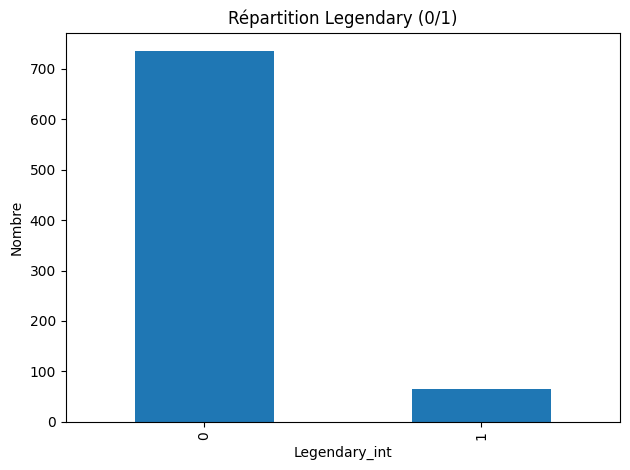

In [59]:
# === Vérifier quelques distributions ===
if "Type 1" in df_pokedex.columns:
    plt.figure()
    df_pokedex["Type 1"].value_counts().head(15).plot(kind="bar")
    plt.title("Top 15 des 'Type 1'")
    plt.xlabel("Type 1"); plt.ylabel("Nombre")
    plt.tight_layout(); plt.show()

if "Legendary_int" in df_pokedex.columns:
    plt.figure()
    df_pokedex["Legendary_int"].value_counts().sort_index().plot(kind="bar")
    plt.title("Répartition Legendary (0/1)")
    plt.xlabel("Legendary_int"); plt.ylabel("Nombre")
    plt.tight_layout(); plt.show()

## Partie 2 — Observations des combats (`Combats.csv`)

Actions :  
- Charger et afficher **structure + 10 premières lignes**.  
- Classer les features (catégorielles, numériques discrètes/continues).  
- **Compter** le nombre de combats par Pokémon (première OU seconde position).  
- **Compter** le nombre de **victoires** par Pokémon.  
- Vérifier **données manquantes** et **infos**.  
- Commentaires rapides sur les résultats.

In [60]:
# === Vérifier quelques distributions ===
from IPython.display import display

try:
    df_combats = pd.read_csv(PATH_COMBATS, sep=None, engine='python')
except FileNotFoundError:
    raise SystemExit(f"Fichier introuvable : {PATH_COMBATS}")

df_combats.head(3)


,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668


In [61]:
# === Structure + aperçu ===
print("Forme (lignes, colonnes) :", df_combats.shape)
print("Colonnes :", list(df_combats.columns))
print("\n")
display(df_combats.head(10))

Forme (lignes, colonnes) : (50000, 3)
Colonnes : ['First_pokemon', 'Second_pokemon', 'Winner']




,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151
5,657,752,657
6,192,134,134
7,73,545,545
8,220,763,763
9,302,31,31


In [62]:
# === Types & catégorisation ===
types_table_c = pd.DataFrame({
    "colonne": df_combats.columns,
    "dtype": [df_combats[c].dtype for c in df_combats.columns]
})
display(types_table_c)

categorical_cols_c = df_combats.select_dtypes(include=["object"]).columns.tolist()
numeric_cols_c = df_combats.select_dtypes(include=[np.number, "float", "int"]).columns.tolist()

print("\n")
print("Catégorielles :", categorical_cols_c)
print("Numériques    :", numeric_cols_c)

# === Discrètes vs continues ===
numeric_discrete_c, numeric_continuous_c = [], []
for c in numeric_cols_c:
    unique_n = df_combats[c].nunique(dropna=True)
    (numeric_discrete_c if unique_n <= 20 else numeric_continuous_c).append(c)

print("Numériques discrètes :", numeric_discrete_c)
print("Numériques continues :", numeric_continuous_c)


,colonne,dtype
0,First_pokemon,int64
1,Second_pokemon,int64
2,Winner,int64




Catégorielles : []
Numériques    : ['First_pokemon', 'Second_pokemon', 'Winner']
Numériques discrètes : []
Numériques continues : ['First_pokemon', 'Second_pokemon', 'Winner']


In [63]:
# === Données manquantes + info() ===
missing_counts_c = df_combats.isna().sum().sort_values(ascending=False)
display(missing_counts_c.to_frame("nb_manquants"))
df_combats.info()


,nb_manquants
First_pokemon,0
Second_pokemon,0
Winner,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   First_pokemon   50000 non-null  int64
 1   Second_pokemon  50000 non-null  int64
 2   Winner          50000 non-null  int64
dtypes: int64(3)
memory usage: 1.1 MB


In [64]:
# === Détection des colonnes clés (first/second/winner) ===
def norm(s): return s.lower().replace(" ", "_").replace("-", "_")

col_first = col_second = col_winner = None
for c in df_combats.columns:
    nc = norm(c)
    if ("first" in nc and "pokemon" in nc) or nc in {"first_pokemon","pokemon1","id_pokemon1"}:
        col_first = c
    if ("second" in nc and "pokemon" in nc) or nc in {"second_pokemon","pokemon2","id_pokemon2"}:
        col_second = c
    if "winner" in nc or nc in {"vainqueur","gagnant","winner_id"}:
        col_winner = c

print("First_pokemon  ->", col_first)
print("Second_pokemon ->", col_second)
print("Winner         ->", col_winner)

if not all([col_first, col_second, col_winner]):
    print("! Vérifiez que les colonnes existent bien dans le fichier")

First_pokemon  -> First_pokemon
Second_pokemon -> Second_pokemon
Winner         -> Winner


In [65]:
# === Nombre de combats menés par Pokémon (ID) ===
if col_first and col_second:
    counts_first  = df_combats[col_first].value_counts()
    counts_second = df_combats[col_second].value_counts()
    fights_count = counts_first.add(counts_second, fill_value=0).astype(int)
    fights_count.name = "battles"

    battles_df = fights_count.sort_values(ascending=False).to_frame()
    print("Top 15 — Combats par Pokémon (ID)")
    display(battles_df.head(15))
else:
    fights_count = None
    print("! Colonnes first/second manquantes : impossible de compter les combats.")


Top 15 — Combats par Pokémon (ID)


,battles
163,164
344,160
667,159
214,158
758,158
79,157
762,156
690,156
374,155
708,154


In [66]:
# === Victoires par Pokémon (ID) ===
if col_winner:
    wins_count = df_combats[col_winner].value_counts().astype(int)
    wins_count.name = "wins"

    wins_df = wins_count.sort_values(ascending=False).to_frame()
    print("Top 15 — Victoires par Pokémon (ID)")
    display(wins_df.head(15))
else:
    wins_count = None
    print("! Colonne winner manquante : impossible de compter les victoires.")

Top 15 — Victoires par Pokémon (ID)


,wins
Winner,
163,152
154,136
438,136
428,134
314,133
432,133
214,130
394,130
249,128


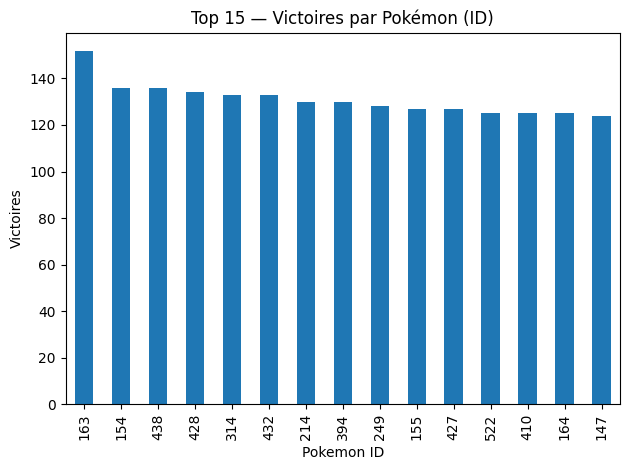

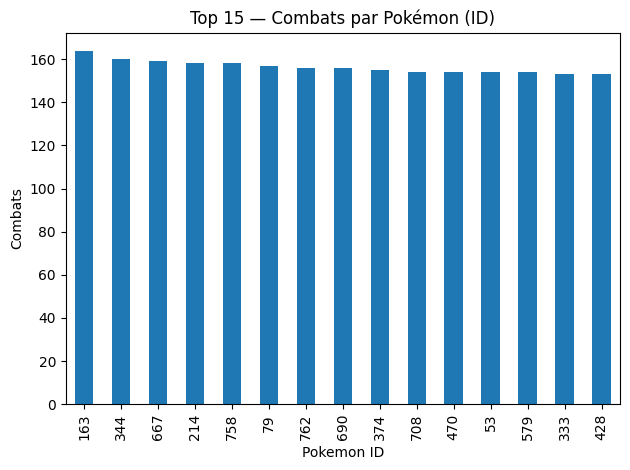

In [67]:
# Représentation
if "wins_count" in locals() and isinstance(wins_count, pd.Series):
    plt.figure()
    wins_count.sort_values(ascending=False).head(15).plot(kind="bar")
    plt.title("Top 15 — Victoires par Pokémon (ID)")
    plt.xlabel("Pokemon ID"); plt.ylabel("Victoires")
    plt.tight_layout(); plt.show()

if "fights_count" in locals() and isinstance(fights_count, pd.Series):
    plt.figure()
    fights_count.sort_values(ascending=False).head(15).plot(kind="bar")
    plt.title("Top 15 — Combats par Pokémon (ID)")
    plt.xlabel("Pokemon ID"); plt.ylabel("Combats")
    plt.tight_layout(); plt.show()


In [68]:
# Commentaires
n_rows = len(df_combats)
n_unique_pokemon = None
if col_first and col_second:
    ids_all = pd.Index(df_combats[col_first]).append(pd.Index(df_combats[col_second]))
    n_unique_pokemon = ids_all.nunique()

print(f"- Nombre d'observations (combats) : {n_rows}")
if n_unique_pokemon is not None:
    print(f"- Nombre de Pokémons distincts impliqués : {n_unique_pokemon}")

if "wins_count" in locals() and isinstance(wins_count, pd.Series) and not wins_count.empty:
    top_winner_id = wins_count.idxmax()
    top_winner_wins = int(wins_count.max())
    print(f"- Meilleur vainqueur (ID) : {top_winner_id} avec {top_winner_wins} victoires")

if ("fights_count" in locals() and isinstance(fights_count, pd.Series)
    and "wins_count" in locals() and isinstance(wins_count, pd.Series)):
    never_won_ids = fights_count.index.difference(wins_count.index)
    print(f"- Pokémons sans aucune victoire : {len(never_won_ids)}")


- Nombre d'observations (combats) : 50000
- Nombre de Pokémons distincts impliqués : 784
- Meilleur vainqueur (ID) : 163 avec 152 victoires
- Pokémons sans aucune victoire : 1


## Partie 3 — Agrégation avec le Pokédex

Objectif : vue centralisée par Pokémon ID :  
- (a) Nombre de combats menés (`battles`)  
- (b) Nombre de victoires (`wins`)  
- (c) Taux de victoire = `wins / battles`  
- (d) Jointure avec Pokédex pour récupérer `Name` (et d'autres colonnes utiles).  
- Export CSV final.

In [69]:
# === Vérifs et détection colonnes clés (first / second / winner) ===
from IPython.display import display

if 'df_combats' not in globals():
    raise SystemExit("df_combats est introuvable. Exécutez la Partie 2 (chargement des combats).")
if 'df_pokedex' not in globals():
    raise SystemExit("df_pokedex est introuvable. Exécutez l’Étape 3 (chargement du Pokédex).")

def _norm(s):
    return str(s).lower().replace(" ", "_").replace("-", "_")

col_first = col_second = col_winner = None
for c in df_combats.columns:
    nc = _norm(c)
    if ("first" in nc and "pokemon" in nc) or nc in {"first_pokemon","pokemon1","id_pokemon1"}:
        col_first = c
    if ("second" in nc and "pokemon" in nc) or nc in {"second_pokemon","pokemon2","id_pokemon2"}:
        col_second = c
    if "winner" in nc or nc in {"vainqueur","gagnant","winner_id"}:
        col_winner = c

print("Colonnes détectées →",
      f"First: {col_first} | Second: {col_second} | Winner: {col_winner}")

Colonnes détectées → First: First_pokemon | Second: Second_pokemon | Winner: Winner


In [70]:
# === Séries 'fights_count' et 'wins_count' ===
if not col_first or not col_second or not col_winner:
    raise SystemExit("Colonnes clés manquantes. Vérifiez les noms dans df_combats.")

counts_first  = df_combats[col_first].value_counts()
counts_second = df_combats[col_second].value_counts()

fights_count = counts_first.add(counts_second, fill_value=0).astype(int)
fights_count.name = "battles"

wins_count = df_combats[col_winner].value_counts().astype(int)
wins_count.name = "wins"

print("Top 5 — Combats :")
display(fights_count.sort_values(ascending=False).head(5).to_frame())

print("\nTop 5 — Victoires :")
display(wins_count.sort_values(ascending=False).head(5).to_frame())

Top 5 — Combats :


,battles
163,164
344,160
667,159
214,158
758,158



Top 5 — Victoires :


,wins
Winner,
163,152
154,136
438,136
428,134
314,133


In [71]:
# === Table d'agrégation par ID + liste Python ===
all_ids = sorted(set(fights_count.index.tolist()) | set(wins_count.index.tolist()))

agg = pd.DataFrame({
    "PokemonId": all_ids,
    "battles": [int(fights_count.get(i, 0)) for i in all_ids],
    "wins":    [int(wins_count.get(i, 0))   for i in all_ids],
})
agg["win_rate"] = (agg["wins"] / agg["battles"]).replace([np.inf, -np.inf], np.nan).fillna(0)
agg["win_rate_pct"] = (agg["win_rate"] * 100).round(1)

display(agg.head(10))

# version "liste" Python
liste_pokemon_combats = agg.to_dict(orient="records")
print(f"Longueur de la liste : {len(liste_pokemon_combats)} | Exemple 2 entrées :")
print(liste_pokemon_combats[:2])


,PokemonId,battles,wins,win_rate,win_rate_pct
0,1,133,37,0.278195,27.8
1,2,121,46,0.380165,38.0
2,3,132,89,0.674242,67.4
3,4,125,70,0.560000,56.0
4,5,112,55,0.491071,49.1
5,6,118,64,0.542373,54.2
6,7,133,115,0.864662,86.5
7,8,139,119,0.856115,85.6
8,9,135,114,0.844444,84.4
9,10,117,19,0.162393,16.2


Longueur de la liste : 784 | Exemple 2 entrées :
[{'PokemonId': 1, 'battles': 133, 'wins': 37, 'win_rate': 0.2781954887218045, 'win_rate_pct': 27.8}, {'PokemonId': 2, 'battles': 121, 'wins': 46, 'win_rate': 0.38016528925619836, 'win_rate_pct': 38.0}]


In [76]:
# === Jointure avec Pokedex pour récupérer le nom ===

norm = lambda s: s.strip().lower().replace(' ', '')
cibles = {'#','number','no','id','pokemonid','pokedex_number','pokedexnumber','national_number'}

key_pokedex = next((c for c in df_pokedex.columns if norm(c) in cibles), None)

if key_pokedex is None:
    key_pokedex = next(
        (c for c in df_pokedex.select_dtypes(include=[np.number]).columns
         if df_pokedex[c].nunique(dropna=True) == len(df_pokedex)),
        None
    )

if key_pokedex is None:
    raise SystemExit("Colonne ID introuvable.")

df_pk = df_pokedex.copy()
try: df_pk[key_pokedex] = df_pk[key_pokedex].astype(int)
except: pass

merged = agg.merge(df_pk, how="left", left_on="PokemonId", right_on=key_pokedex)
cols = ["PokemonId", "battles", "wins", "win_rate_pct"] + (["Name"] if "Name" in merged.columns else [])
new_pokedex = merged[cols].sort_values(["wins","battles","win_rate_pct"], ascending=[False, False, False])

display(new_pokedex.head(15))
print("\nClé Pokédex utilisée :", key_pokedex)

,PokemonId,battles,wins,win_rate_pct
155,163,164,152,92.7
426,438,149,136,91.3
146,154,141,136,96.5
416,428,153,134,87.6
304,314,150,133,88.7
420,432,145,133,91.7
205,214,158,130,82.3
383,394,139,130,93.5
239,249,135,128,94.8
415,427,134,127,94.8



Clé Pokédex utilisée : NUMERO


In [77]:
# === Noms + victoires (+ %) ===
agg['PokemonId'] = agg['PokemonId'].astype(int)

df_pk = df_pokedex.copy()
try:
    df_pk[key_pokedex] = df_pk[key_pokedex].astype(int)
except:
    pass
df_pk = df_pk.drop_duplicates(subset=[key_pokedex])

merged = agg.merge(df_pk, how="left", left_on="PokemonId", right_on=key_pokedex)

name_col = 'Name' if 'Name' in merged.columns else ('Name_filled' if 'Name_filled' in merged.columns else None)
if name_col:
    pokedex_victoires = merged[[name_col, 'PokemonId', 'wins', 'battles', 'win_rate_pct']].rename(columns={name_col: 'Name'})
else:
    pokedex_victoires = merged[['PokemonId', 'wins', 'battles', 'win_rate_pct']]

pokedex_victoires = pokedex_victoires.sort_values(['wins', 'win_rate_pct'], ascending=[False, False])
display(pokedex_victoires.head(20))

,PokemonId,wins,battles,win_rate_pct
155,163,152,164,92.7
146,154,136,141,96.5
426,438,136,149,91.3
416,428,134,153,87.6
420,432,133,145,91.7
304,314,133,150,88.7
383,394,130,139,93.5
205,214,130,158,82.3
239,249,128,135,94.8
147,155,127,129,98.4


------------------------------------------------------------
SECONDE PARTIE — Analyse
------------------------------------------------------------

TITRE TP 2-1 – Pokémon : Seconde partie (Analyse)

**CONTEXTE**

 Dans la première partie, un tableau agrégé par Pokémon (combats, victoires, pourcentage de victoires) a été construit. Cette seconde partie décrit statistiquement le jeu d’observations, visualise quelques distributions utiles et explore des corrélations simples.

**OBJECTIFS**

Reprendre l’essentiel de la partie 1 (chargement, agrégation, tableau final nouveauPokedex).
Décrire le jeu d’observations.
Visualiser les types les plus courants.
Étudier les types gagnants/perdants.
Explorer des corrélations (heatmap).
Sauvegarder le dataset final.

**PRÉREQUIS**

Pandas 0.24.2, NumPy 1.16.3, Matplotlib 3.0.3, Seaborn 0.9.0.


**DONNÉES**

Pokedex.csv, Combats.csv. Les chemins déjà définis PATH_POKEDEX, PATH_COMBATS seront réutilisés

In [78]:
# importer les modules demandé
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

sns.set()

In [79]:
# charger Pokedex et Combats en réutilisant PATH_*
from pathlib import Path
from IPython.display import display

PATH_POKEDEX = Path(globals().get('PATH_POKEDEX', 'Pokedex.csv'))
PATH_COMBATS = Path(globals().get('PATH_COMBATS', 'Combats.csv'))

if not PATH_POKEDEX.exists():
    PATH_POKEDEX = Path('datas/pokedex.csv')
if not PATH_COMBATS.exists():
    PATH_COMBATS = Path('datas/combats.csv')

df_pokedex = pd.read_csv(PATH_POKEDEX, sep=None, engine='python')
df_combats = pd.read_csv(PATH_COMBATS, sep=None, engine='python')

print('Tailles : Pokedex', df_pokedex.shape, '| Combats', df_combats.shape)
display(df_pokedex.head(5))
display(df_combats.head(5))

Tailles : Pokedex (800, 12) | Combats (50000, 3)


,NUMERO,NOM,TYPE_1,TYPE_2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE
0,1,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,FAUX
1,2,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,FAUX
2,3,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,FAUX
3,4,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,FAUX
4,5,Salamèche,Feu,NaN,39,52,43,60,50,65,1,FAUX


,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151


In [80]:
# Harmoniser les colonnes utiles (ID, nom, types, légendaire)
def pick(colnames, *cands):
    for c in cands:
        if c in colnames:
            return c
    return None

cols = df_pokedex.columns
col_id   = pick(cols, '#','NUMERO','Number','number','id','ID','No','no')
col_name = pick(cols, 'Name','NOM','Nom')
col_t1   = pick(cols, 'Type 1','TYPE_1','Type1')
col_t2   = pick(cols, 'Type 2','TYPE_2','Type2')
col_leg  = pick(cols, 'Legendary','LEGENDAIRE','legendary')

df_pk = df_pokedex.copy()
if col_leg is not None:
    df_pk['Legendary_int'] = df_pk[col_leg].map({
        True:1, False:0, 'True':1, 'False':0, 'VRAI':1, 'FAUX':0, 'Oui':1, 'Non':0, 1:1, 0:0
    }).fillna(0).astype(int)

rename_map = {}
if col_id:   rename_map[col_id]   = 'PokemonId'
if col_name: rename_map[col_name] = 'Name'
if col_t1:   rename_map[col_t1]   = 'Type1'
if col_t2:   rename_map[col_t2]   = 'Type2'
df_pk = df_pk.rename(columns=rename_map)

if 'PokemonId' in df_pk.columns:
    try:
        df_pk['PokemonId'] = df_pk['PokemonId'].astype(int)
    except:
        pass

from IPython.display import display
display(df_pk[['PokemonId','Name','Type1','Type2']].head(8))

,PokemonId,Name,Type1,Type2
0,1,Bulbizarre,Herbe,Poison
1,2,Herbizarre,Herbe,Poison
2,3,Florizarre,Herbe,Poison
3,4,Mega Florizarre,Herbe,Poison
4,5,Salamèche,Feu,NaN
5,6,Reptincel,Feu,NaN
6,7,Dracaufeu,Feu,Vol
7,8,Mega Dracaufeu X,Feu,Dragon


In [81]:
# Calculer combats menés, victoires et construire nouveauPokedex
def _norm(s):
    return str(s).lower().replace(' ', '_').replace('-', '_')

col_first = col_second = col_winner = None
for c in df_combats.columns:
    nc = _norm(c)
    if ('first' in nc and 'pokemon' in nc) or nc in {'first_pokemon','pokemon1','id_pokemon1'}:  col_first  = c
    if ('second' in nc and 'pokemon' in nc) or nc in {'second_pokemon','pokemon2','id_pokemon2'}: col_second = c
    if 'winner' in nc or nc in {'vainqueur','gagnant','winner_id'}:                                col_winner = c

counts_first  = df_combats[col_first].value_counts()
counts_second = df_combats[col_second].value_counts()
fights_count  = counts_first.add(counts_second, fill_value=0).astype(int)
wins_count    = df_combats[col_winner].value_counts().astype(int)

all_ids = sorted(set(fights_count.index) | set(wins_count.index))
agg = pd.DataFrame({
    'PokemonId': all_ids,
    'battles': [int(fights_count.get(i,0)) for i in all_ids],
    'wins':    [int(wins_count.get(i,0))   for i in all_ids],
})
agg['win_rate'] = (agg['wins']/agg['battles']).replace([np.inf,-np.inf], np.nan).fillna(0)
agg['win_rate_pct'] = (agg['win_rate']*100).round(1)

if 'PokemonId' in df_pk.columns:
    df_pk = df_pk.drop_duplicates(subset=['PokemonId'])
    nouveauPokedex = agg.merge(df_pk, how='left', on='PokemonId')
else:
    nouveauPokedex = agg.copy()

from IPython.display import display
display(nouveauPokedex.head(10))

,PokemonId,battles,wins,win_rate,win_rate_pct,Name,Type1,Type2,POINTS_DE_VIE,POINTS_ATTAQUE,POINTS_DEFFENCE,POINTS_ATTAQUE_SPECIALE,POINT_DEFENSE_SPECIALE,POINTS_VITESSE,NOMBRE_GENERATIONS,LEGENDAIRE,Legendary_int
0,1,133,37,0.278195,27.8,Bulbizarre,Herbe,Poison,45,49,49,65,65,45,1,FAUX,0
1,2,121,46,0.380165,38.0,Herbizarre,Herbe,Poison,60,62,63,80,80,60,1,FAUX,0
2,3,132,89,0.674242,67.4,Florizarre,Herbe,Poison,80,82,83,100,100,80,1,FAUX,0
3,4,125,70,0.560000,56.0,Mega Florizarre,Herbe,Poison,80,100,123,122,120,80,1,FAUX,0
4,5,112,55,0.491071,49.1,Salamèche,Feu,NaN,39,52,43,60,50,65,1,FAUX,0
5,6,118,64,0.542373,54.2,Reptincel,Feu,NaN,58,64,58,80,65,80,1,FAUX,0
6,7,133,115,0.864662,86.5,Dracaufeu,Feu,Vol,78,84,78,109,85,100,1,FAUX,0
7,8,139,119,0.856115,85.6,Mega Dracaufeu X,Feu,Dragon,78,130,111,130,85,100,1,FAUX,0
8,9,135,114,0.844444,84.4,Mega Dracaufeu Y,Feu,Vol,78,104,78,159,115,100,1,FAUX,0
9,10,117,19,0.162393,16.2,Carapuce,Eau,NaN,44,48,65,50,64,43,1,FAUX,0


In [82]:
# Décrire les colonnes numériques (count, mean, std, min, quartiles, max)
desc = nouveauPokedex.select_dtypes(include=[np.number]).describe().T
from IPython.display import display
display(desc[['count','mean','std','min','25%','50%','75%','max']])

,count,mean,std,min,25%,50%,75%,max
PokemonId,784.0,402.654337,230.232187,1.0,204.750000,402.500000,601.250000,800.000000
battles,784.0,127.551020,11.393236,92.0,120.000000,128.000000,135.000000,164.000000
wins,784.0,63.775510,32.983848,0.0,36.000000,61.500000,91.000000,152.000000
win_rate,784.0,0.500899,0.255459,0.0,0.283704,0.490906,0.717374,0.984496
win_rate_pct,784.0,50.089668,25.545188,0.0,28.375000,49.100000,71.725000,98.400000
POINTS_DE_VIE,784.0,69.077806,25.393311,1.0,50.000000,65.000000,80.000000,255.000000
POINTS_ATTAQUE,784.0,78.919643,32.575170,5.0,55.000000,75.000000,100.000000,190.000000
POINTS_DEFFENCE,784.0,73.899235,31.360815,5.0,50.000000,70.000000,90.000000,230.000000
POINTS_ATTAQUE_SPECIALE,784.0,72.758929,32.729033,10.0,50.000000,65.000000,95.000000,194.000000
POINT_DEFENSE_SPECIALE,784.0,71.951531,27.811906,20.0,50.000000,70.000000,90.000000,230.000000


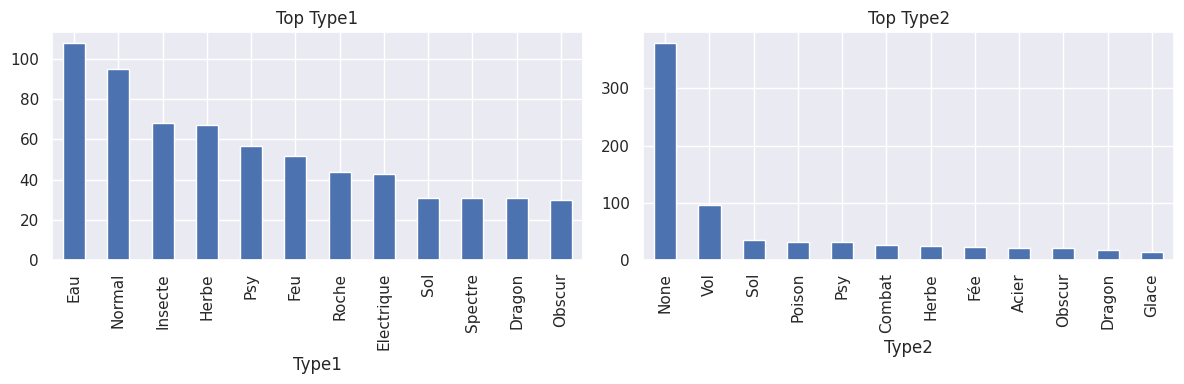

In [83]:
# Visualiser les types les plus présents (Type1 et Type2)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
if 'Type1' in nouveauPokedex.columns:
    nouveauPokedex['Type1'].value_counts().head(12).plot(kind='bar', ax=axes[0], title='Top Type1')
if 'Type2' in nouveauPokedex.columns:
    nouveauPokedex['Type2'].fillna('None').value_counts().head(12).plot(kind='bar', ax=axes[1], title='Top Type2')
plt.tight_layout()
plt.show()

In [84]:
# Moyenne du pourcentage de victoires par type (ordre croissant)
from IPython.display import display
if 'Type1' in nouveauPokedex.columns:
    t1 = (nouveauPokedex.groupby('Type1')['win_rate_pct']
          .mean().sort_values(ascending=True).round(1))
    display(t1.to_frame('win_rate_pct_mean'))

if 'Type2' in nouveauPokedex.columns:
    t2 = (nouveauPokedex.assign(Type2=nouveauPokedex['Type2'].fillna('None'))
          .groupby('Type2')['win_rate_pct']
          .mean().sort_values(ascending=True).round(1))
    display(t2.to_frame('win_rate_pct_mean'))

,win_rate_pct_mean
Type1,
Fée,32.9
E,34.4
Roche,40.5
Acier,42.4
Insecte,43.3
Poison,43.3
Glace,44.0
Herbe,44.0
Eau,47.0


,win_rate_pct_mean
Type2,
Roche,28.5
Sol,37.6
Eau,41.2
Herbe,42.0
Fée,43.2
Insecte,43.9
Spectre,44.1
Poison,45.2
None,46.6


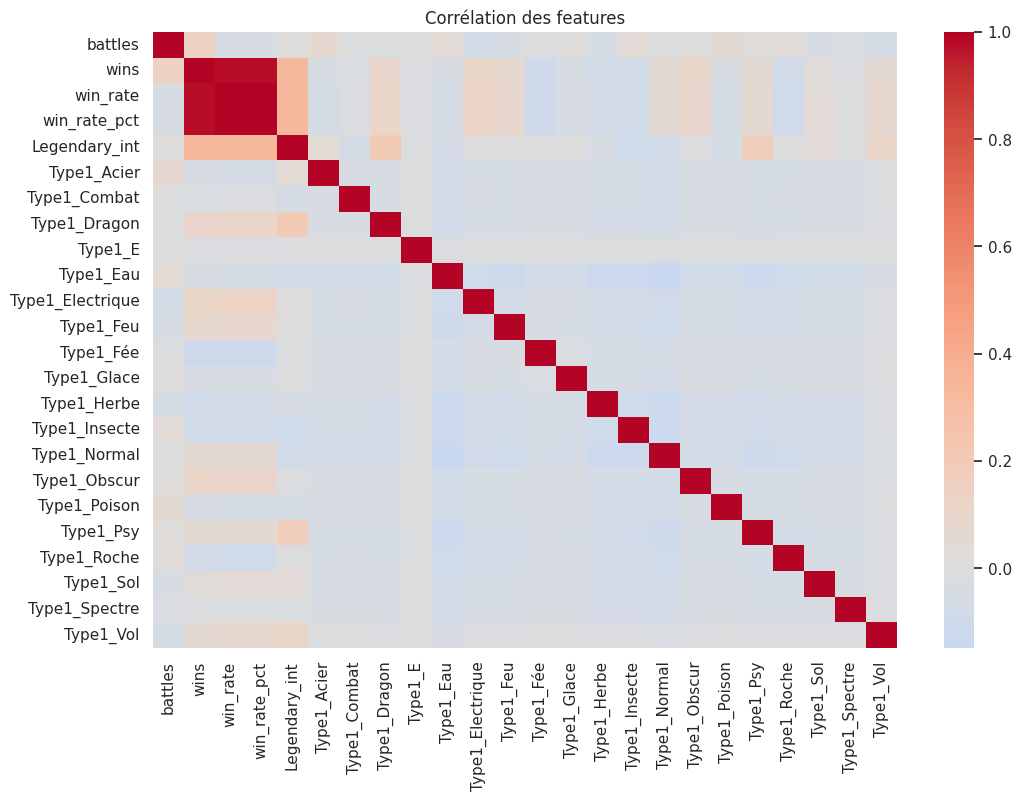

In [85]:
# Calculer et tracer une heatmap de corrélations
num_cols_base = ['battles','wins','win_rate','win_rate_pct','Legendary_int',
                 'HP','Attack','Defense','Sp. Atk','Sp. Def','Speed','Total']
num_cols = [c for c in num_cols_base if c in nouveauPokedex.columns]

df_corr = nouveauPokedex[num_cols].copy()
if 'Type1' in nouveauPokedex.columns:
    dummies_t1 = pd.get_dummies(nouveauPokedex['Type1'], prefix='Type1', dummy_na=False)
    df_corr = pd.concat([df_corr, dummies_t1], axis=1)

corr = df_corr.corr()
plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Corrélation des features')
plt.show()

In [86]:
# Exporter le tableau final
nouveauPokedex.to_csv('dataset.csv', index=False)
print('Exporté : dataset.csv')

Exporté : dataset.csv


# SECONDE PARTIE — Apprentissage (modélisation)
Cette section utilise les tableaux préparés précédemment (Pokedex, combats, agrégation) pour construire un jeu d’entraînement, entraîner un modèle simple de prédiction du gagnant, évaluer rapidement ses performances et produire des prédictions avec le fichier tests.csv.

In [87]:
# Construire une table d'entraînement à partir des combats et des stats du Pokédex
import numpy as np
import pandas as pd

def _norm(s): return str(s).lower().replace(' ', '_').replace('-', '_')

col_first = col_second = col_winner = None
for c in df_combats.columns:
    nc = _norm(c)
    if ('first' in nc and 'pokemon' in nc) or nc in {'first_pokemon','pokemon1','id_pokemon1'}:  col_first  = c
    if ('second' in nc and 'pokemon' in nc) or nc in {'second_pokemon','pokemon2','id_pokemon2'}: col_second = c
    if 'winner' in nc or nc in {'vainqueur','gagnant','winner_id'}:                                col_winner = c

if 'PokemonId' not in df_pk.columns:
    raise SystemExit("Kolonne 'PokemonId' absente du Pokédex harmonisé (df_pk).")

stat_cols_all = ['HP','Attack','Defense','Sp. Atk','Sp. Def','Speed','Total']
stat_cols = [c for c in stat_cols_all if c in df_pk.columns]
aux_cols = ['Legendary_int'] if 'Legendary_int' in df_pk.columns else []

df_left  = df_pk[['PokemonId'] + stat_cols + aux_cols].copy().rename(columns={k:f"{k}_A" for k in stat_cols + aux_cols})
df_right = df_pk[['PokemonId'] + stat_cols + aux_cols].copy().rename(columns={k:f"{k}_B" for k in stat_cols + aux_cols})

tmp = df_combats[[col_first, col_second, col_winner]].copy()
tmp = tmp.rename(columns={col_first:'A', col_second:'B', col_winner:'Winner'})

train = (tmp.merge(df_left, how='left', left_on='A', right_on='PokemonId')
           .merge(df_right, how='left', left_on='B', right_on='PokemonId'))

X_parts = []
for c in stat_cols + aux_cols:
    a, b = f"{c}_A", f"{c}_B"
    if a in train.columns and b in train.columns:
        X_parts.append(train[a] - train[b])

X = pd.concat(X_parts, axis=1)
X.columns = [f"diff_{c}" for c in stat_cols + aux_cols]

y = (train['Winner'] == train['A']).astype(int)

print('Forme X, y :', X.shape, y.shape)
display(X.head(5))


Forme X, y : (50000, 1) (50000,)


,diff_Legendary_int
0,0
1,0
2,0
3,0
4,0


In [88]:
# Découper entraînement/test et entraîner un modèle simple (LogisticRegression)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

clf = Pipeline([
    ('scaler', StandardScaler(with_mean=True, with_std=True)),
    ('lr', LogisticRegression(solver='liblinear', max_iter=1000))
])

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
print('Accuracy (test) : %.3f' % acc)
print('\nRapport de classification :\n', classification_report(y_test, y_pred))


Accuracy (test) : 0.568

Rapport de classification :
               precision    recall  f1-score   support

           0       0.55      0.97      0.70      6600
           1       0.77      0.12      0.21      5900

    accuracy                           0.57     12500
   macro avg       0.66      0.54      0.46     12500
weighted avg       0.66      0.57      0.47     12500



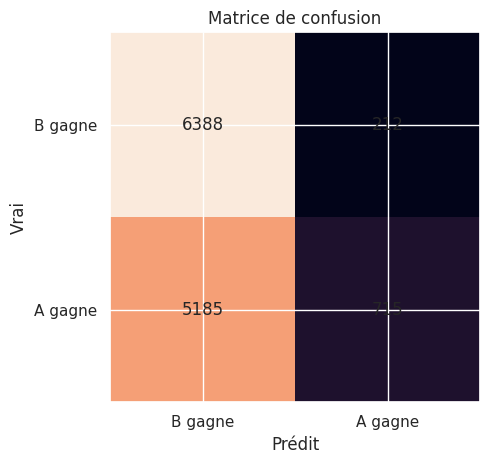

In [89]:
# Afficher une matrice de confusion (matplotlib)
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0,1])
fig = plt.figure()
plt.imshow(cm, interpolation='nearest')
plt.title('Matrice de confusion')
plt.xlabel('Prédit'); plt.ylabel('Vrai')
plt.xticks([0,1], ['B gagne','A gagne']); plt.yticks([0,1], ['B gagne','A gagne'])
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, str(v), ha='center', va='center')
plt.tight_layout()
plt.show()

In [90]:
# Comparer à une règle simple basée sur win_rate
if 'win_rate' in agg.columns:
    wr = agg['win_rate']
    def predict_wr(a, b):
        s1, s2 = wr.get(a, 0), wr.get(b, 0)
        if s1 == s2:
            return 1 if int(a) < int(b) else 0
        return 1 if s1 > s2 else 0  # 1 => A gagne

    y_pred_wr = []
    for a, b in zip(train.loc[X_test.index, 'A'], train.loc[X_test.index, 'B']):
        y_pred_wr.append(predict_wr(int(a), int(b)))
    y_pred_wr = np.array(y_pred_wr)
    acc_wr = (y_pred_wr == y_test.values).mean()
    print('Accuracy (règle win_rate) : %.3f' % acc_wr)
else:
    print("Colonne 'win_rate' indisponible : baseline non calculée.")

Accuracy (règle win_rate) : 0.526


In [91]:
# Prédire un fichier tests.csv (col. First/Second détectées automatiquement)
from pathlib import Path

PATH_TESTS = Path(globals().get('PATH_TESTS', 'tests.csv'))
if PATH_TESTS.exists():
    df_tests = pd.read_csv(PATH_TESTS, sep=None, engine='python')
    c1=c2=None
    for c in df_tests.columns:
        nc=_norm(c)
        if ('first' in nc and 'pokemon' in nc) or nc in {'first_pokemon','pokemon1','id_pokemon1'}: c1=c
        if ('second' in nc and 'pokemon' in nc) or nc in {'second_pokemon','pokemon2','id_pokemon2'}: c2=c
    if not c1 or not c2:
        print("Colonnes des paires non trouvées dans tests.csv")
    else:
        tests = df_tests[[c1,c2]].rename(columns={c1:'A', c2:'B'})
        tests = (tests.merge(df_left, how='left', left_on='A', right_on='PokemonId')
                      .merge(df_right, how='left', left_on='B', right_on='PokemonId'))
        X_parts_t = []
        for c in stat_cols + aux_cols:
            a, b = f"{c}_A", f"{c}_B"
            if a in tests.columns and b in tests.columns:
                X_parts_t.append(tests[a] - tests[b])
        X_test_pred = pd.concat(X_parts_t, axis=1)
        X_test_pred.columns = [f"diff_{c}" for c in stat_cols + aux_cols]
        pred_winA = clf.predict(X_test_pred)
        out = df_tests.copy()
        out['Predicted_winner'] = np.where(pred_winA==1, tests['A'], tests['B']).astype(int)
        out.to_csv('predictions_model.csv', index=False)
        print('Exporté : predictions_model.csv')
else:
    print('tests.csv non trouvé — étape sautée.')

Exporté : predictions_model.csv


# DERNIÈRE PARTIE — Qui sera le vainqueur ?

Cette section décide du vainqueur pour une paire de Pokémons. Elle utilise le modèle entraîné s’il est présent, sinon une règle simple basée sur le pourcentage de victoires (win_rate).

In [92]:
# Vérifier les prérequis (df_pk, agg, df_combats) et fixer les colonnes de stats
import numpy as np
import pandas as pd

if 'df_pk' not in globals():
    raise SystemExit("df_pk manquant (Pokédex harmonisé).")
if 'agg' not in globals():
    raise SystemExit("agg manquant (battles, wins, win_rate).")
if 'df_combats' not in globals():
    raise SystemExit("df_combats manquant (historique des combats).")

stat_cols_all = ['HP','Attack','Defense','Sp. Atk','Sp. Def','Speed','Total']
STAT_COLS = [c for c in stat_cols_all if c in df_pk.columns]
AUX_COLS = ['Legendary_int'] if 'Legendary_int' in df_pk.columns else []

if 'PokemonId' not in df_pk.columns:
    raise SystemExit("Colonne 'PokemonId' absente de df_pk.")

# tables auxiliaires (ID -> stats)
left  = df_pk[['PokemonId'] + STAT_COLS + AUX_COLS].copy().rename(columns={c:f"{c}_A" for c in STAT_COLS + AUX_COLS})
right = df_pk[['PokemonId'] + STAT_COLS + AUX_COLS].copy().rename(columns={c:f"{c}_B" for c in STAT_COLS + AUX_COLS})

wr_map = agg.set_index('PokemonId')['win_rate']


In [93]:
# Fonctions utilitaires pour features et prédiction
def _features_for_pair(pid_a: int, pid_b: int) -> pd.DataFrame:
    df_a = left[left['PokemonId'] == pid_a]
    df_b = right[right['PokemonId'] == pid_b]
    if df_a.empty or df_b.empty:
        raise ValueError("ID inconnu dans le Pokédex harmonisé.")
    tmp = df_a.merge(df_b, how='cross')
    parts = []
    for c in STAT_COLS + AUX_COLS:
        a, b = f"{c}_A", f"{c}_B"
        parts.append(tmp[a].reset_index(drop=True) - tmp[b].reset_index(drop=True))
    X = pd.concat(parts, axis=1)
    X.columns = [f"diff_{c}" for c in STAT_COLS + AUX_COLS]
    return X

def _predict_with_model(pid_a: int, pid_b: int):
    X = _features_for_pair(pid_a, pid_b)
    if 'clf' not in globals():
        return None
    try:
        proba = float(getattr(clf, "predict_proba")(X)[:,1][0])  # proba que A gagne
    except Exception:
        try:
            proba = float(clf.predict(X)[0])
            proba = 1.0 if proba == 1 else 0.0
        except Exception:
            return None
    pred = pid_a if proba >= 0.5 else pid_b
    return pred, proba

def _predict_with_rule(pid_a: int, pid_b: int):
    s1, s2 = float(wr_map.get(pid_a, 0.0)), float(wr_map.get(pid_b, 0.0))
    if s1 != s2:
        pred = pid_a if s1 > s2 else pid_b
        proba = max(s1, s2)
        return pred, proba
    # égalité -> tie-break par Total si dispo, sinon plus petit ID
    score_map = df_pk.set_index('PokemonId')[STAT_COLS].sum(axis=1, numeric_only=True) if STAT_COLS else pd.Series(dtype=float)
    t1, t2 = float(score_map.get(pid_a, 0.0)), float(score_map.get(pid_b, 0.0))
    if t1 != t2:
        return (pid_a, 0.5) if t1 > t2 else (pid_b, 0.5)
    return (pid_a if int(pid_a) < int(pid_b) else pid_b, 0.5)

def predict_winner(pid_a: int, pid_b: int):
    res = _predict_with_model(pid_a, pid_b)
    if isinstance(res, tuple):
        return {"A": pid_a, "B": pid_b, "winner": res[0], "confidence": round(res[1], 3), "method": "model"}
    pred, conf = _predict_with_rule(pid_a, pid_b)
    return {"A": pid_a, "B": pid_b, "winner": pred, "confidence": round(conf, 3), "method": "win_rate_rule"}

In [94]:
# Démonstration sur quelques paires de df_combats
def _norm(s): return str(s).lower().replace(' ', '_').replace('-', '_')

col_first = col_second = None
for c in df_combats.columns:
    nc = _norm(c)
    if ('first' in nc and 'pokemon' in nc) or nc in {'first_pokemon','pokemon1','id_pokemon1'}:  col_first  = c
    if ('second' in nc and 'pokemon' in nc) or nc in {'second_pokemon','pokemon2','id_pokemon2'}: col_second = c

demo = []
for _, r in df_combats[[col_first, col_second]].head(10).iterrows():
    out = predict_winner(int(r[col_first]), int(r[col_second]))
    demo.append(out)

pd.DataFrame(demo)


,A,B,winner,confidence,method
0,266,298,298,0.470,model
1,702,701,701,0.470,model
2,191,668,668,0.470,model
3,237,683,683,0.470,model
4,151,231,231,0.470,model
5,657,752,752,0.470,model
6,192,134,134,0.470,model
7,73,545,545,0.174,model
8,220,763,763,0.470,model
9,302,31,31,0.470,model


In [100]:
# Prédire un fichier tests.csv et retourner un tableau prêt à l’export
from pathlib import Path
PATH_TESTS = Path(globals().get('PATH_TESTS', 'tests.csv'))

if PATH_TESTS.exists():
    df_tests = pd.read_csv(PATH_TESTS, sep=None, engine='python')
    c1 = c2 = None
    for c in df_tests.columns:
        nc = _norm(c)
        if ('first' in nc and 'pokemon' in nc) or nc in {'first_pokemon','pokemon1','id_pokemon1'}: c1 = c
        if ('second' in nc and 'pokemon' in nc) or nc in {'second_pokemon','pokemon2','id_pokemon2'}: c2 = c
    if not c1 or not c2:
        raise SystemExit("Colonnes des paires non trouvées dans tests.csv.")
    preds = []
    for _, row in df_tests.iterrows():
        preds.append(predict_winner(int(row[c1]), int(row[c2])))
    out = df_tests.copy()
    out['Predicted_winner'] = [d['winner'] for d in preds]
    out['Confidence'] = [d['confidence'] for d in preds]
    out['Method'] = [d['method'] for d in preds]
    out.head(10)
else:
    print("tests.csv non trouvé.")


In [101]:
# Evaluer la méthode sur l’historique des combats
if 'Winner' in df_combats.columns:
    true_winners = df_combats['Winner'].astype(int).values
else:
    # détection souple
    wcol = next((c for c in df_combats.columns if 'winner' in _norm(c) or _norm(c) in {'vainqueur','gagnant','winner_id'}), None)
    if not wcol:
        raise SystemExit("Colonne 'Winner' introuvable pour l'évaluation.")
    true_winners = df_combats[wcol].astype(int).values

preds_eval = []
for _, r in df_combats[[col_first, col_second]].iterrows():
    preds_eval.append(predict_winner(int(r[col_first]), int(r[col_second]))['winner'])

accuracy = (np.array(preds_eval) == true_winners).mean()
print(f"Accuracy sur l'historique : {accuracy:.3f}")

Accuracy sur l'historique : 0.570
